# Tutorial 2: finned-tube models

A finned-tube heat battery is a block of phase-change material (PCM) crossed by parallel
tubes that carry the heat transfer fluid (HTF), usually water. Thin metal fins (annular
discs around each tube) carry the heat into the PCM, which conducts poorly on its own.

All the tubes are the same, so the models describe one tube and the storage around it, and
multiply the device totals by the number of tubes. Around a tube of radius $R_f$ and length
$Z$, the storage reaches out to a radius $R_f + D$, about half the distance to the next
tube, where no heat crosses by symmetry. The positions are

- $z$, along the tube from the inlet,
- $y$, the distance from the tube axis, from $R_f$ to $R_f + D$,
- $x$, across the gap between two fins (only in the mush model).

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pybamm

import pytes

parameter_values = pytes.SharpFrontModel().default_parameter_values
for name in [
    "Number of tubes",
    "Tube length [m]",
    "Tube radius [m]",
    "Storage depth [m]",
    "Fin thickness [m]",
    "Fin pitch [m]",
]:
    print(f"{name}: {parameter_values[name]}")

Number of tubes: 1
Tube length [m]: 10
Tube radius [m]: 0.003
Storage depth [m]: 0.02
Fin thickness [m]: 0.0002
Fin pitch [m]: 0.003


## The equations

The fluid carries its specific enthalpy $h$ along the tube and gains heat from the wall:

$$
A \rho \frac{\partial h}{\partial t} + \dot m \frac{\partial h}{\partial z} = q',
$$

where $A$ is the flow area of the tube, $\dot m$ the mass flow rate in it and $q'$ the heat
the fluid gains per unit length of tube. Inside the storage, heat is conducted by the
enthalpy method: the enthalpy per unit volume $H$, which includes the latent heat, evolves as

$$
\frac{\partial H}{\partial t} = \nabla \cdot \left( k \nabla T \right),
$$

with the temperature $T(H)$ and the conductivity $k$ given by the material. At the tube wall
the heat flux from the fluid into the storage is $h_c (T_f - T_s)$, with $h_c$ the heat
transfer coefficient, $T_f$ the fluid temperature and $T_s$ the storage temperature at the
wall. The two models of this family differ in how they treat the fins.

**Sharp-front model** (`pytes.SharpFrontModel`). The PCM and the fins are homogenised into
one composite material, with volume-averaged heat capacity and conductivity. Heat is
conducted radially, in $y$, at each point $z$ along the tube: a two-dimensional model.

**Mush model** (`pytes.MushModel`). The fins and the PCM are resolved separately. Heat flows
from the fluid into the fin roots, radially along the fins (in $y$), and from each fin into
the PCM on either side (in $x$), at each point along the tube: a three-dimensional model.

Each model is a fixed composition of submodels, which you can inspect:

In [2]:
for model in [pytes.SharpFrontModel(), pytes.MushModel()]:
    print(model.name)
    for name, submodel in model.submodels.items():
        print(f"    {name}: {type(submodel).__name__}")

Sharp front model
    fluid: AdvectedFluid
    storage: EnthalpyStorage
    coupling: WallCoupling
    device energy: DeviceEnergy
Mush model
    fluid: AdvectedFluid
    storage: EnthalpyStorage
    fins: EnthalpyStorage
    coupling: FinRootCoupling
    fin-PCM coupling: FinStorageCoupling
    device energy: DeviceEnergy


`model.print_submodel_info()` lists, for each submodel, the variables it needs and
provides, its parameters and its assumptions.

## The melting front

Both models start with the default discharge: the battery uniform at 70 °C, with water at
10 °C flowing in. The liquid fraction in the storage shows the PCM solidifying, first near
the tube and the inlet, then outwards and along the tube.

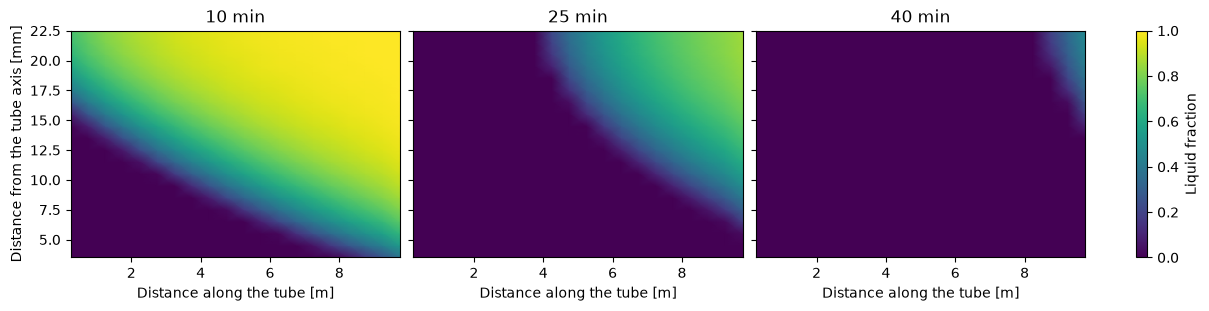

In [3]:
sharp_front = pytes.SharpFrontModel()
t_eval = np.linspace(0, 3600, 121)
solution = pybamm.Simulation(sharp_front).solve([0, 3600], t_interp=t_eval)

liquid_fraction = solution["Liquid fraction"]
y = liquid_fraction.mesh.nodes
z = solution["Heat transfer fluid temperature [K]"].mesh.nodes

fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True, layout="constrained")
for ax, minutes in zip(axes, [10, 25, 40], strict=True):
    field = ax.pcolormesh(
        z,
        1e3 * y,
        liquid_fraction(t=60 * minutes, y=y, z=z),
        vmin=0,
        vmax=1,
        shading="gouraud",
    )
    ax.set_title(f"{minutes} min")
    ax.set_xlabel("Distance along the tube [m]")
axes[0].set_ylabel("Distance from the tube axis [mm]")
fig.colorbar(field, ax=axes, label="Liquid fraction")
plt.show()

## Resolved or averaged along the tube

By default, the storage is resolved at every point along the tube, so a model captures how
the fluid cools as it passes the warm PCM, and how the solidification front moves along the
tube. With the option `"storage along flow path": "averaged"`, one storage cross-section
stands for the average along the tube instead, and exchanges heat with the fluid averaged
along it. That removes one dimension: the sharp-front model becomes one-dimensional, and the
mush model two-dimensional.

Below, each model runs in both forms. The resolved mush model uses a coarser mesh than its
default, so that it solves in a few seconds; its default mesh gives the same outlet
temperature to within 0.2 K.

sharp front, resolved    0.75 s
sharp front, averaged    0.18 s


mush, resolved           3.74 s


mush, averaged           1.62 s


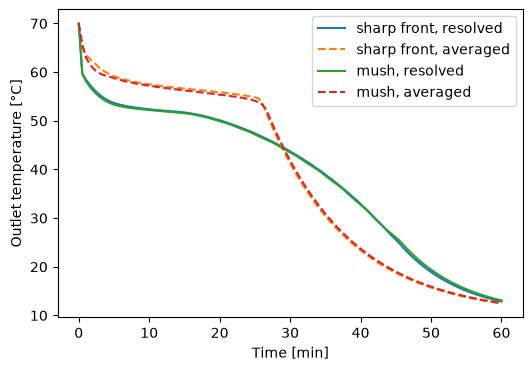

In [4]:
averaged = {"storage along flow path": "averaged"}
mush = pytes.MushModel()
runs = {
    "sharp front, resolved": (sharp_front, None),
    "sharp front, averaged": (pytes.SharpFrontModel(options=averaged), None),
    "mush, resolved": (mush, {mush.x: 10, mush.y: 10, mush.z: 10}),
    "mush, averaged": (pytes.MushModel(options=averaged), None),
}
solutions = {}
for label, (model, var_pts) in runs.items():
    start = time.perf_counter()
    simulation = pybamm.Simulation(model, var_pts=var_pts)
    solutions[label] = simulation.solve([0, 3600], t_interp=t_eval)
    elapsed = time.perf_counter() - start
    print(f"{label:22s} {elapsed:6.2f} s")

fig, ax = plt.subplots(figsize=(6, 4))
for label, sol in solutions.items():
    style = "-" if "resolved" in label else "--"
    ax.plot(
        sol["Time [min]"].entries,
        sol["Outlet temperature [degC]"].entries,
        style,
        label=label,
    )
ax.set_xlabel("Time [min]")
ax.set_ylabel("Outlet temperature [°C]")
ax.legend()
plt.show()

The two models agree closely, resolved or averaged: with these thin, closely spaced fins,
homogenising them barely changes the result. The mush model is the one to use when the fins
are thicker or further apart, or when the temperature between the fins matters.

The averaged forms are many times faster, and they store and deliver the same energy, but
they change the shape of the outlet temperature. In an averaged model the whole storage sees
the fluid averaged along the tube, so it gives up its heat evenly along the tube instead of
from the inlet onwards. Early on, it keeps more of the fluid warm and the outlet stays
hotter; later, the whole storage is spent at once and the outlet falls faster. The averaged
models suit quick estimates of the energy and the duration of a discharge, and studies with
many runs; the resolved models are needed for the outlet temperature over time.

Every variant has the same outputs, conserves energy exactly, and runs the same experiments
(Tutorial 6). The next tutorial does the same for the packed-bed family.